# ChiliEdgeNet-C14 — (3/3) Ablation & Compression

Nap model de xuat tu NB1 (`c14_s2_seed42.pth`) roi:
- **Ablation** (bo tung khoi / tung ky thuat LLM) — train lai cac bien the nho.
- **Nen mo hinh** — pruning sweep + Dynamic INT8 + FP16.

**Input can attach:** (1) dataset anh goc, (2) output NB1 chua `c14_s2_seed42.pth`.
_Ablation train lai nhieu bien the nen notebook nay hoi nang._

In [1]:
!pip install -q torchinfo

In [2]:
import os, gc, warnings
import numpy as np
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as T
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader
from torchinfo import summary as torchinfo_summary
from sklearn.metrics import classification_report, confusion_matrix, f1_score, recall_score
from sklearn.utils.class_weight import compute_class_weight
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings('ignore')

torch.manual_seed(42); torch.cuda.manual_seed_all(42)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE} | seed=42')

Device: cuda | seed=42


In [3]:
# Config
DATASET_PATH = '/kaggle/input/datasets/tminhhi/ot-21-06/dataset_smartcrop_plit_300'
TRAIN_DIR = os.path.join(DATASET_PATH, 'train')
VAL_DIR   = os.path.join(DATASET_PATH, 'val')
TEST_DIR  = os.path.join(DATASET_PATH, 'test')

IMG_SIZE, BATCH_SIZE = 224, 32
EPOCHS = 30
LR_BACKBONE, LR_NEW = 1e-4, 1e-3
PRETRAINED = True
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

LABEL_SMOOTHING = 0.05
WARMUP_FRAC     = 0.1

# Tiny-LLM Transformer: reduce 96 -> 128, 1 khoi, 196 token
TF_EMBED_DIM, TF_DEPTH = 128, 1
TF_HEADS, TF_KV_HEADS = 4, 2
TF_MLP_RATIO, TF_DROP, TF_ROPE_BASE = 2.0, 0.1, 100.0

# Điểm cắt backbone (features[1:BACKBONE_CUT]):
#   8..14 -> lưới 14x14 = 196 token   (14 -> 96ch, 672K)
#   15    -> lưới 7x7   =  49 token   (160ch, 835K) — features[14] là tầng stride-32
BACKBONE_CUT = 14

# Muc nhieu ap o test-time (khong co mat luc train)
EVAL_SETS_CFG = ['clean', 'blur2', 'dark']   # them 'noise'/'jpeg' neu muon
BLUR_K, DARK_SCALE = 7, 0.4
ISO_SHIFT, ISO_INT = 0.02, 0.1
JPEG_Q = 30

             train  val  test  total
anthracnose    264   81    62    407
healthy        334  102    78    514
leaf_curl      328  104    82    514
leaf_spot      326  101    76    503
yellow_leaf    345  103    75    523
TONG          1597  491   373   2461


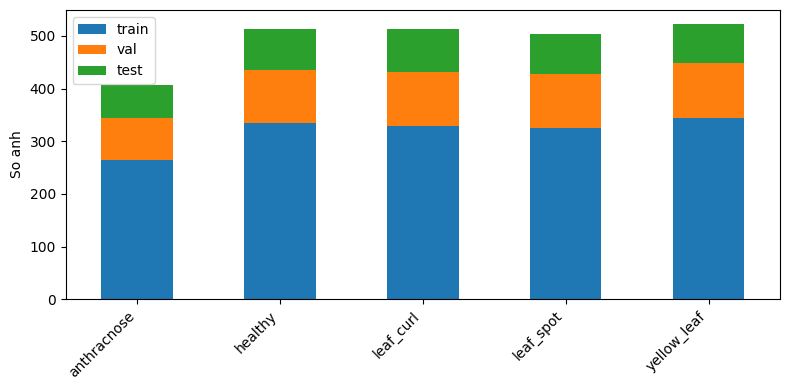

NUM_CLASSES=5 | ['anthracnose', 'healthy', 'leaf_curl', 'leaf_spot', 'yellow_leaf']
Balanced (ratio=1.31) -> no weighting


In [4]:
# Dataset: class names + distribution + class weights
_ds = ImageFolder(TRAIN_DIR)
class_names = _ds.classes
NUM_CLASSES = len(class_names)
counts = np.bincount([l for _, l in _ds.samples], minlength=NUM_CLASSES)

import pandas as pd
_dist = {}
for _split, _d in [('train', TRAIN_DIR), ('val', VAL_DIR), ('test', TEST_DIR)]:
    _n = np.bincount([l for _, l in ImageFolder(_d).samples], minlength=NUM_CLASSES)
    _dist[_split] = _n
dist_df = pd.DataFrame(_dist, index=class_names)
dist_df['total'] = dist_df.sum(axis=1)
dist_df.loc['TONG'] = dist_df.sum()
print(dist_df.to_string())
dist_df.to_csv('c14_class_distribution.csv')

fig, ax = plt.subplots(figsize=(max(8, NUM_CLASSES * 0.9), 4))
dist_df.drop(index='TONG')[['train', 'val', 'test']].plot(kind='bar', stacked=True, ax=ax)
ax.set_ylabel('So anh'); plt.xticks(rotation=45, ha='right')
plt.tight_layout(); plt.savefig('c14_class_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

print(f'NUM_CLASSES={NUM_CLASSES} | {class_names}')
ratio = counts.max() / counts.min()
if ratio >= 1.5:
    cw = compute_class_weight('balanced', classes=np.arange(NUM_CLASSES),
                              y=np.array([l for _, l in _ds.samples]))
    CLASS_WEIGHTS = torch.tensor(cw, dtype=torch.float32)
    print(f'Imbalanced (ratio={ratio:.2f}) -> class weights ON')
else:
    CLASS_WEIGHTS = None
    print(f'Balanced (ratio={ratio:.2f}) -> no weighting')
del _ds

In [5]:
# ===== TINY-LLM TRANSFORMER (RMSNorm + RoPE-2D + GQA) — dong gop chinh cua model =====
class RMSNorm(nn.Module):
    """Chuan hoa theo RMS (khong tru mean nhu LayerNorm) — nhe hon, dung trong LLM (LLaMA)."""
    def __init__(self, dim, eps=1e-6):
        super().__init__(); self.eps, self.weight = eps, nn.Parameter(torch.ones(dim))
    def forward(self, x):
        return x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps) * self.weight

def build_axial_rope(gh, gw, head_dim, base=100.0):
    """RoPE-2D: sinh cos/sin ma hoa vi tri (hang, cot) cua luoi token bang phep xoay.
    Nua dau head_dim cho toa do y (hang), nua sau cho x (cot). 0 tham so hoc.
    Tra (cos_y, sin_y, cos_x, sin_x)."""
    d = head_dim // 2
    assert d % 2 == 0, 'head_dim phai chia het 4'
    inv = 1.0 / (base ** (torch.arange(0, d, 2).float() / d))
    gy = torch.arange(gh).float().view(gh, 1).expand(gh, gw).reshape(-1)
    gx = torch.arange(gw).float().view(1, gw).expand(gh, gw).reshape(-1)
    ey = torch.cat([torch.outer(gy, inv)] * 2, dim=-1)
    ex = torch.cat([torch.outer(gx, inv)] * 2, dim=-1)
    return ey.cos()[None,None], ey.sin()[None,None], ex.cos()[None,None], ex.sin()[None,None]

def _rot_half(x):
    """Phep xoay cua RoPE trong khong gian embedding: [x1, x2] -> [-x2, x1]."""
    x1, x2 = x[..., :x.shape[-1]//2], x[..., x.shape[-1]//2:]
    return torch.cat((-x2, x1), dim=-1)

def apply_rope2d(t, cy, sy, cx, sx):
    """Ap RoPE-2D: nua dau embedding xoay theo y, nua sau xoay theo x."""
    d = t.shape[-1] // 2
    ty, tx = t[..., :d], t[..., d:]
    ty = ty * cy + _rot_half(ty) * sy
    tx = tx * cx + _rot_half(tx) * sx
    return torch.cat([ty, tx], dim=-1)

class GroupedQueryAttention(nn.Module):
    """Attention kieu LLM: nh query head dung chung nkv KV head (nh > nkv)
    -> giam tham so & bo nho so voi Multi-Head Attention chuan. O day nh=4, nkv=2."""
    def __init__(self, dim, nh, nkv, dropout=0.0):
        super().__init__()
        assert dim % nh == 0 and nh % nkv == 0
        self.nh, self.nkv, self.hd = nh, nkv, dim // nh
        self.groups, self.scale = nh // nkv, (dim // nh) ** -0.5
        self.q = nn.Linear(dim, nh * self.hd, bias=False)
        self.k = nn.Linear(dim, nkv * self.hd, bias=False)
        self.v = nn.Linear(dim, nkv * self.hd, bias=False)
        self.o = nn.Linear(nh * self.hd, dim, bias=False)
        self.ad, self.pd = nn.Dropout(dropout), nn.Dropout(dropout)
    def forward(self, x, rope):
        B, N, _ = x.shape; cy, sy, cx, sx = rope
        q = self.q(x).view(B, N, self.nh, self.hd).transpose(1, 2)
        k = self.k(x).view(B, N, self.nkv, self.hd).transpose(1, 2)
        v = self.v(x).view(B, N, self.nkv, self.hd).transpose(1, 2)
        q, k = apply_rope2d(q, cy, sy, cx, sx), apply_rope2d(k, cy, sy, cx, sx)  # gan vi tri vao q,k
        if self.groups > 1:                              # lap KV cho du so query head
            k = k.repeat_interleave(self.groups, dim=1)
            v = v.repeat_interleave(self.groups, dim=1)
        attn = self.ad(((q @ k.transpose(-2, -1)) * self.scale).softmax(-1))
        return self.pd(self.o((attn @ v).transpose(1, 2).reshape(B, N, -1)))

class TinyLLMBlock(nn.Module):
    """1 khoi transformer kieu LLM: pre-RMSNorm + GQA(RoPE) residual, roi pre-RMSNorm + MLP(GELU) residual."""
    def __init__(self, dim, nh, nkv, mlp_ratio=2.0, dropout=0.1):
        super().__init__()
        self.n1 = RMSNorm(dim); self.attn = GroupedQueryAttention(dim, nh, nkv, dropout)
        self.n2 = RMSNorm(dim); h = int(dim * mlp_ratio)
        self.mlp = nn.Sequential(nn.Linear(dim, h), nn.GELU(), nn.Dropout(dropout),
                                 nn.Linear(h, dim), nn.Dropout(dropout))
    def forward(self, x, rope):
        x = x + self.attn(self.n1(x), rope)
        return x + self.mlp(self.n2(x))

# ===== MODEL DE XUAT: ChiliEdgeNet (khop 100% class dung de train o NB1) =====
class ChiliEdgeNet(nn.Module):
    """MobileNetV2 cat som (features[0:cut]) trich dac trung -> Conv1x1 giam chieu ve embed_dim
    -> chuoi 196 token (14x14) -> depth khoi Tiny-LLM Transformer -> pool trung binh -> phan lop."""
    def __init__(self, num_classes, pretrained=True, cut=BACKBONE_CUT,
                 embed_dim=TF_EMBED_DIM, depth=TF_DEPTH, heads=TF_HEADS, kv_heads=TF_KV_HEADS,
                 mlp_ratio=TF_MLP_RATIO, drop=TF_DROP, rope_base=TF_ROPE_BASE):
        super().__init__()
        w = torchvision.models.MobileNet_V2_Weights.IMAGENET1K_V1 if pretrained else None
        base = torchvision.models.mobilenet_v2(weights=w)
        self.first_conv = base.features[0]
        self.backbone = nn.Sequential(*list(base.features[1:cut]))
        # suy ra so kenh + kich thuoc luoi ra cua backbone (chay thu 1 tensor rong)
        with torch.no_grad():
            feat = self.backbone(self.first_conv(torch.zeros(1,3,IMG_SIZE,IMG_SIZE)))
        c_out, grid = feat.shape[1], feat.shape[2]
        self.reduce = nn.Sequential(nn.Conv2d(c_out, embed_dim, 1, bias=False),   # giam kenh -> embed_dim
                                    nn.BatchNorm2d(embed_dim), nn.GELU())
        self.emb_drop = nn.Dropout(drop)
        cy, sy, cx, sx = build_axial_rope(grid, grid, embed_dim // heads, base=rope_base)
        for n, b in zip(['rcy','rsy','rcx','rsx'], [cy, sy, cx, sx]):
            self.register_buffer(n, b, persistent=False)     # RoPE la buffer, khong phai tham so hoc
        self.encoder = nn.ModuleList([TinyLLMBlock(embed_dim, heads, kv_heads, mlp_ratio, drop)
                                      for _ in range(depth)])
        self.norm = RMSNorm(embed_dim)
        self.drop = nn.Dropout(0.2)
        self.fc = nn.Linear(embed_dim, num_classes)
        print(f'[ChiliEdgeNet] backbone out: {c_out}ch @ {grid}x{grid} -> {grid*grid} token')
    def forward(self, x):
        x = self.backbone(self.first_conv(x))                            # CNN trich dac trung
        x = self.emb_drop(self.reduce(x).flatten(2).transpose(1, 2))     # (B,C,H,W) -> (B, HxW token, embed)
        rope = (self.rcy, self.rsy, self.rcx, self.rsx)
        for blk in self.encoder:
            x = blk(x, rope)
        return self.fc(self.drop(self.norm(x).mean(dim=1)))              # pool token -> phan lop

print('ChiliEdgeNet loaded.')

def build_main():
    """Tao model de xuat cuoi cung (ChiliEdgeNet): cut=14, CNN backbone + Tiny-LLM Transformer.
    KHONG con TripletAttention/RES_Block (da bi loai khoi kien truc de xuat tu NB1)."""
    return ChiliEdgeNet(NUM_CLASSES, pretrained=PRETRAINED).to(DEVICE)

ChiliEdgeNet loaded.


In [6]:
# ===== Helpers: seed, loss/optimizer/scheduler, vong train & eval, bao cao =====
import math, random

SEED = 42

def set_seed(seed=SEED):
    """Co dinh moi nguon ngau nhien (Python / NumPy / PyTorch CPU + CUDA) de tai lap."""
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

def make_criterion():
    """CrossEntropy + label smoothing; tu gan class_weights neu dataset lech lop."""
    weight = CLASS_WEIGHTS.to(DEVICE) if CLASS_WEIGHTS is not None else None
    return nn.CrossEntropyLoss(weight=weight, label_smoothing=LABEL_SMOOTHING)

def make_optimizer(model):
    """Adam 2 nhom learning-rate: backbone (pretrained) hoc cham, phan moi hoc nhanh."""
    backbone_prefix = ('first_conv', 'backbone')
    backbone_params = [p for name, p in model.named_parameters()
                       if p.requires_grad and name.startswith(backbone_prefix)]
    new_params      = [p for name, p in model.named_parameters()
                       if p.requires_grad and not name.startswith(backbone_prefix)]
    return torch.optim.Adam(
        [{'params': backbone_params, 'lr': LR_BACKBONE},
         {'params': new_params,      'lr': LR_NEW}], lr=LR_NEW)

def make_scheduler(optimizer, epochs):
    """Linear warmup (WARMUP_FRAC epoch dau) roi cosine decay ve 0."""
    warmup = max(1, int(WARMUP_FRAC * epochs))
    def lr_scale(epoch):                              # epoch: 0-indexed
        if epoch < warmup:
            return (epoch + 1) / warmup               # tang tuyen tinh
        progress = (epoch - warmup) / max(1, epochs - warmup)
        return 0.5 * (1 + math.cos(math.pi * progress))   # cosine giam dan
    return torch.optim.lr_scheduler.LambdaLR(optimizer, lr_scale)

def train_one_epoch(model, loader, optimizer, criterion):
    """Chay 1 epoch train; tra ve (loss trung binh, accuracy) tren tap train."""
    model.train()
    total_loss = correct = seen = 0
    for images, labels in loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * images.size(0)
        correct    += (logits.argmax(1) == labels).sum().item()
        seen       += images.size(0)
    return total_loss / seen, correct / seen

@torch.no_grad()
def evaluate(model, loader, criterion):
    """Danh gia khong cap nhat gradient; tra ve (loss, accuracy, du_doan, nhan_that)."""
    model.eval()
    total_loss = correct = seen = 0
    preds, labels_all = [], []
    for images, labels in loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        logits = model(images)
        total_loss += criterion(logits, labels).item() * images.size(0)
        pred = logits.argmax(1)
        correct += (pred == labels).sum().item()
        seen    += images.size(0)
        preds      += pred.cpu().tolist()
        labels_all += labels.cpu().tolist()
    return total_loss / seen, correct / seen, preds, labels_all

def train_model(model, train_loader, val_loader, criterion, ckpt_path, epochs=None):
    """Train + validate moi epoch, luu checkpoint TOT NHAT theo val_acc, reload truoc khi tra ve."""
    epochs = epochs or EPOCHS
    optimizer = make_optimizer(model)
    scheduler = make_scheduler(optimizer, epochs)
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    best_val_acc = 0.0
    for epoch in range(1, epochs + 1):
        train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, criterion)
        val_loss, val_acc, _, _ = evaluate(model, val_loader, criterion)
        scheduler.step()
        for key, value in zip(history, [train_loss, val_loss, train_acc, val_acc]):
            history[key].append(value)
        print(f'Epoch {epoch:2d}/{epochs} | train {train_acc:.4f} | val {val_acc:.4f}')
        if val_acc > best_val_acc:                    # chi luu khi val_acc cai thien
            best_val_acc = val_acc
            torch.save(model.state_dict(), ckpt_path)
    model.load_state_dict(torch.load(ckpt_path, map_location=DEVICE))   # reload best truoc khi test
    return history

def count_params(model):
    """Tong so tham so cua model."""
    return sum(p.numel() for p in model.parameters())

def report(tag, model, loader):
    """In accuracy / F1-macro / recall-macro / params + classification_report per-class."""
    _, acc, preds, labels_all = evaluate(model, loader, make_criterion())
    f1     = f1_score(labels_all, preds, average='macro')
    recall = recall_score(labels_all, preds, average='macro')
    print(f'[{tag}] acc={acc:.4f} f1={f1:.4f} recall={recall:.4f} params={count_params(model):,}')
    print(classification_report(labels_all, preds, target_names=class_names, digits=4))
    return acc, f1, preds, labels_all

def plot_cm(labels_all, preds, title, path, cmap='Blues'):
    """Ve + luu confusion matrix (dpi=300)."""
    cm = confusion_matrix(labels_all, preds)
    fig, ax = plt.subplots(figsize=(max(6, NUM_CLASSES), max(5, NUM_CLASSES - 1)))
    sns.heatmap(cm, annot=True, fmt='d', cmap=cmap,
                xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set_xlabel('Predicted'); ax.set_ylabel('True')
    plt.tight_layout(); plt.savefig(path, dpi=300, bbox_inches='tight'); plt.show()

def plot_curve(history, title, path):
    """Ve + luu learning curve (loss & accuracy theo epoch)."""
    epochs_range = range(1, len(history['train_loss']) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(14, 5))
    ax[0].plot(epochs_range, history['train_loss'], label='train')
    ax[0].plot(epochs_range, history['val_loss'], label='val')
    ax[0].set_title('Loss'); ax[0].legend(); ax[0].grid(alpha=0.3)
    ax[1].plot(epochs_range, history['train_acc'], label='train')
    ax[1].plot(epochs_range, history['val_acc'], label='val')
    ax[1].set_title('Accuracy'); ax[1].legend(); ax[1].grid(alpha=0.3)
    plt.tight_layout(); plt.savefig(path, dpi=300, bbox_inches='tight'); plt.show()

print('Helpers loaded (label smoothing + cosine warmup).')

Helpers loaded (label smoothing + cosine warmup).


In [7]:
# ===== Loaders (KHONG train) =====
tf_plain = T.Compose([T.Resize((IMG_SIZE, IMG_SIZE)), T.ToTensor(), T.Normalize(MEAN, STD)])
train_loader1 = DataLoader(ImageFolder(TRAIN_DIR, tf_plain), BATCH_SIZE, shuffle=True,  num_workers=4, pin_memory=True)
val_loader1   = DataLoader(ImageFolder(VAL_DIR,   tf_plain), BATCH_SIZE, shuffle=False, num_workers=4, pin_memory=True)
test_loader1  = DataLoader(ImageFolder(TEST_DIR,  tf_plain), BATCH_SIZE, shuffle=False, num_workers=4, pin_memory=True)

tf_aug = T.Compose([T.Resize((IMG_SIZE, IMG_SIZE)), T.RandomRotation(30),
                    T.ColorJitter(0.3, 0.3, 0.2, 0.1), T.RandomHorizontalFlip(),
                    T.RandomAffine(degrees=0, translate=(0.1, 0.1), scale=(0.85, 1.15), shear=10),
                    T.ToTensor(), T.Normalize(MEAN, STD)])
train_loader2 = DataLoader(ImageFolder(TRAIN_DIR, tf_aug), BATCH_SIZE, shuffle=True, num_workers=4, pin_memory=True)
val_loader2, test_loader2 = val_loader1, test_loader1
print('Loaders san sang (khong train).')

Loaders san sang (khong train).


In [8]:
# ===== Nap model da train tu NB1 (C14_1_Train) qua checkpoint =====
import glob

def _find_ckpt(fname):
    cands = [fname, './' + fname] + sorted(glob.glob('/kaggle/input/**/' + fname, recursive=True))
    return next((p for p in cands if os.path.exists(p)), None)

CKPT_S2 = _find_ckpt(f'c14_s2_seed{SEED}.pth')
CKPT_S1 = _find_ckpt(f'c14_s1_seed{SEED}.pth')
print('S2 ckpt:', CKPT_S2)
print('S1 ckpt:', CKPT_S1)
assert CKPT_S2, f'Khong thay c14_s2_seed{SEED}.pth -> hay Add Input output cua NB1 (C14_1_Train)'

set_seed()
model_s2 = build_main()
model_s2.load_state_dict(torch.load(CKPT_S2, map_location=DEVICE))
model_s2.eval()
xai_model = model_s2

model_s1 = None
if CKPT_S1:
    set_seed()
    model_s1 = build_main()
    model_s1.load_state_dict(torch.load(CKPT_S1, map_location=DEVICE))
    model_s1.eval()
print('Da nap model_s2 (de xuat)' + (' + model_s1 (baseline)' if model_s1 is not None else ' | khong co S1'))

S2 ckpt: /kaggle/input/datasets/tminhhi/model-ot/c14_s2_seed123.pth
S1 ckpt: None
Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 162MB/s]


[ChiliEdgeNet] backbone out: 96ch @ 14x14 -> 196 token
Da nap model_s2 (de xuat) | khong co S1


### Dung bo nhieu cho ablation
Cell duoi dung lai code muc benchmark nhieu de tao `ARRS` / `EVAL_SETS` / `predict_arr`
(ablation cham diem tren clean + cac dieu kien nhieu).

In [9]:
# ===== Bo test nhieu: clean + blur/dark/noise/jpeg =====
import io, random
import numpy as np
import pandas as pd
from PIL import Image
from torch.utils.data import Dataset

try:
    import albumentations as A
except ImportError:
    import subprocess; subprocess.run(['pip', 'install', '-q', 'albumentations'], check=True)
    import albumentations as A

_test_raw = ImageFolder(TEST_DIR)
assert _test_raw.classes == class_names
N_TEST = len(_test_raw.samples)
clean_arr = np.zeros((N_TEST, IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8)
labels_arr = np.zeros(N_TEST, dtype=np.int64)
for i, (p, l) in enumerate(_test_raw.samples):
    clean_arr[i] = np.array(Image.open(p).convert('RGB').resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR))
    labels_arr[i] = l

_blur_t = A.GaussianBlur(blur_limit=(BLUR_K, BLUR_K), p=1.0)
_iso_t = A.ISONoise(color_shift=(ISO_SHIFT, ISO_SHIFT), intensity=(ISO_INT, ISO_INT), p=1.0)

def _jpeg_one(img, q=JPEG_Q):
    buf = io.BytesIO()
    Image.fromarray(img).save(buf, format='JPEG', quality=q)
    return np.array(Image.open(buf).convert('RGB'))

ARRS = {'clean': clean_arr}
if 'blur2' in EVAL_SETS_CFG:
    ARRS['blur2'] = np.empty_like(clean_arr)
if 'dark' in EVAL_SETS_CFG:
    ARRS['dark'] = np.clip(clean_arr.astype(np.float32) * DARK_SCALE, 0, 255).astype(np.uint8)
if 'noise' in EVAL_SETS_CFG:
    ARRS['noise'] = np.empty_like(clean_arr)
if 'jpeg' in EVAL_SETS_CFG:
    ARRS['jpeg'] = np.empty_like(clean_arr)

for i in range(N_TEST):
    # Seed truoc moi phep bien doi: GaussianBlur/ISONoise deu boc tham so ngau nhien.
    if 'blur2' in ARRS:
        random.seed(20_000 + i); np.random.seed(20_000 + i)
        if hasattr(_blur_t, 'set_random_seed'):
            try: _blur_t.set_random_seed(20_000 + i)
            except Exception: pass
        ARRS['blur2'][i] = _blur_t(image=clean_arr[i])['image']
    if 'noise' in ARRS:
        random.seed(10_000 + i); np.random.seed(10_000 + i)
        if hasattr(_iso_t, 'set_random_seed'):
            try: _iso_t.set_random_seed(10_000 + i)
            except Exception: pass
        ARRS['noise'][i] = _iso_t(image=clean_arr[i])['image']
    if 'jpeg' in ARRS:
        ARRS['jpeg'][i] = _jpeg_one(clean_arr[i])
EVAL_SETS = list(ARRS)

_MEAN_T = torch.tensor(MEAN).view(3, 1, 1)
_STD_T  = torch.tensor(STD).view(3, 1, 1)

class _ArrDS(Dataset):
    def __init__(self, arr): self.arr = arr
    def __len__(self): return len(self.arr)
    def __getitem__(self, i):
        x = torch.from_numpy(self.arr[i]).permute(2, 0, 1).float().div_(255)
        return (x - _MEAN_T) / _STD_T, int(labels_arr[i])

@torch.no_grad()
def predict_arr(m, arr):
    m.eval(); out = []
    for x, _ in DataLoader(_ArrDS(arr), BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True):
        out += m(x.to(DEVICE)).argmax(1).cpu().tolist()
    return np.array(out)

print(f'{N_TEST} anh x {len(EVAL_SETS)} bo: {EVAL_SETS}')

373 anh x 3 bo: ['clean', 'blur2', 'dark']


---
## Ablation — kiểm tra Triplet Attention và RES_Block theo thiết kế 2×2

Mô hình đề xuất hiện tại (`model_s2`) **không chứa** Triplet Attention và
`RES_Block`. Vì vậy, không thể mô tả thí nghiệm này là tiếp tục cắt hai khối khỏi
kiến trúc hiện tại. Thay vào đó, ta thêm lại các khối ngay sau convolution đầu của
MobileNetV2 theo thứ tự **Triplet Attention → RES_Block**, rồi huấn luyện lại các
cấu hình kiểm soát từ đầu với cùng seed, dữ liệu, recipe và số epoch.

| cấu hình | Triplet Attention | RES_Block | diễn giải |
|---|:---:|:---:|---|
| `with_both` | có | có | mốc đầy đủ để thực hiện phép loại bỏ |
| `triplet_only` | có | không | loại `RES_Block` khỏi `with_both` |
| `resblock_only` | không | có | loại Triplet Attention khỏi `with_both` |
| `current_without_both` (`baseline`) | không | không | loại đồng thời cả hai; chính là mô hình hiện tại |

Hai ablation kiến trúc riêng cũng được huấn luyện lại cùng protocol:

| cấu hình | thay đổi so với mô hình hiện tại |
|---|---|
| `without_tf_block` | bỏ toàn bộ Tiny-LLM Transformer |
| `no_residual` | vô hiệu hóa mọi phép cộng skip trong các `InvertedResidual` thuộc backbone MobileNetV2 đang sử dụng |

`no_residual` chỉ bỏ nhánh đồng nhất `x + F(x)` nhưng vẫn giữ
toàn bộ convolution của từng block. Xóa luôn các block sẽ đồng thời thay đổi độ sâu,
số phép tính và trường tiếp nhận nên không còn là ablation residual thuần túy.

Bảng McNemar ở dưới xuất trực tiếp ba tương phản đã định trước cho Triplet Attention
và `RES_Block`: bỏ `RES_Block`, bỏ Triplet Attention, và bỏ cả hai. Kết quả không có
ý nghĩa thống kê chỉ cho phép viết “chưa quan sát thấy khác biệt”, không tự nó chứng
minh các khối hoàn toàn không có ảnh hưởng; muốn khẳng định không thua kém cần thêm
biên non-inferiority và nhiều seed.


In [ ]:
# ===== Ablation kien truc + factorial 2x2 cho Triplet Attention / RES_Block =====
ABL_EPOCHS = EPOCHS


class ModifiedSENet(nn.Module):
    def __init__(self, c, reduction=16):
        super().__init__()
        rd = max(c // reduction, 4)
        self.avg = nn.AdaptiveAvgPool2d(1)
        self.mx = nn.AdaptiveMaxPool2d(1)
        self.fc = nn.Sequential(
            nn.Linear(c, rd, bias=False), nn.ReLU(inplace=True),
            nn.Linear(rd, c, bias=False), nn.Sigmoid())

    def forward(self, x):
        b, c = x.shape[:2]
        w = self.avg(x).view(b, c) + self.mx(x).view(b, c)
        return x * self.fc(w).view(b, c, 1, 1)


class ECA(nn.Module):
    def __init__(self, c, k=3):
        super().__init__()
        self.avg = nn.AdaptiveAvgPool2d(1)
        self.conv = nn.Conv1d(1, 1, k, padding=k // 2, bias=False)

    def forward(self, x):
        y = self.avg(x).squeeze(-1).transpose(-1, -2)
        y = self.conv(y).transpose(-1, -2).unsqueeze(-1)
        return x * torch.sigmoid(y).expand_as(x)


class RES_Block(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.se = ModifiedSENet(c)
        self.eca = ECA(c)

    def forward(self, x):
        return x + self.eca(self.se(x))


class _ZPool(nn.Module):
    def forward(self, x):
        return torch.cat(
            [x.max(1, keepdim=True)[0], x.mean(1, keepdim=True)], dim=1)


class _AttGate(nn.Module):
    def __init__(self, k=7):
        super().__init__()
        self.zp = _ZPool()
        self.conv = nn.Conv2d(2, 1, k, padding=k // 2, bias=False)
        self.bn = nn.BatchNorm2d(1)

    def forward(self, x):
        return x * torch.sigmoid(self.bn(self.conv(self.zp(x))))


class TripletAttention(nn.Module):
    def __init__(self, k=7):
        super().__init__()
        self.hc = _AttGate(k)
        self.wc = _AttGate(k)
        self.hw = _AttGate(k)

    def forward(self, x):
        y1 = self.hc(x.permute(0, 2, 1, 3).contiguous())
        y1 = y1.permute(0, 2, 1, 3).contiguous()
        y2 = self.wc(x.permute(0, 3, 1, 2).contiguous())
        y2 = y2.permute(0, 2, 3, 1).contiguous()
        return (y1 + y2 + self.hw(x)) / 3.0


class ChiliEdgeNetCNNBlocks(ChiliEdgeNet):
    """ChiliEdgeNet voi hai khoi CNN tuy chon sau first_conv."""
    def __init__(self, num_classes, use_triplet, use_resblock,
                 pretrained=True):
        super().__init__(num_classes, pretrained=pretrained)
        self.use_triplet = use_triplet
        self.use_resblock = use_resblock
        self.triplet1 = TripletAttention(7) if use_triplet else nn.Identity()
        self.res1 = RES_Block(32) if use_resblock else nn.Identity()

    def forward(self, x):
        x = self.first_conv(x)
        x = self.triplet1(x)
        x = self.res1(x)
        x = self.backbone(x)
        x = self.emb_drop(self.reduce(x).flatten(2).transpose(1, 2))
        rope = (self.rcy, self.rsy, self.rcx, self.rsx)
        for blk in self.encoder:
            x = blk(x, rope)
        return self.fc(self.drop(self.norm(x).mean(dim=1)))


# Baseline (model_s2) = current_without_both = (Triplet=False, RES=False).
# Ba cau hinh duoi duoc train moi de tao factorial 2x2 day du.
FACTORIAL_VARIANTS = {
    'with_both':      {'use_triplet': True,  'use_resblock': True},
    'triplet_only':   {'use_triplet': True,  'use_resblock': False},
    'resblock_only':  {'use_triplet': False, 'use_resblock': True},
}
ABLATION_LAYERS = [
    'tf_block', 'no_residual',
] + list(FACTORIAL_VARIANTS)

VARIANT_DESCRIPTION = {
    'tf_block': 'without_tf_block',
    'no_residual': (
        'disable every active MobileNetV2 InvertedResidual skip connection'),
    'with_both': 'add Triplet Attention + RES_Block',
    'triplet_only': 'add Triplet Attention only (remove RES_Block from with_both)',
    'resblock_only': 'add RES_Block only (remove Triplet Attention from with_both)',
}


def disable_mobilenetv2_residuals(model):
    """Tat moi identity skip x + F(x) trong backbone MobileNetV2 dang dung."""
    disabled = 0
    for block in model.backbone:
        if bool(getattr(block, 'use_res_connect', False)):
            block.use_res_connect = False
            disabled += 1
    if disabled == 0:
        raise RuntimeError('Khong tim thay residual connection nao trong backbone')
    model.disabled_backbone_residuals = disabled
    return disabled


def make_ablated(key):
    """Tao mot cau hinh chua train trong ablation da dinh nghia truoc."""
    if key == 'tf_block':
        m = build_main()
        m.encoder = nn.ModuleList([])
    elif key == 'no_residual':
        m = build_main()
        disabled = disable_mobilenetv2_residuals(m)
        print(f'[no_residual] disabled {disabled} skip connections')
    elif key in FACTORIAL_VARIANTS:
        m = ChiliEdgeNetCNNBlocks(
            NUM_CLASSES, pretrained=PRETRAINED, **FACTORIAL_VARIANTS[key])
    else:
        raise ValueError(f'khong biet bien the: {key}')
    return m.to(DEVICE)


_full = count_params(model_s2)
print(f'baseline = current_without_both (model_s2): {_full:,} params')
for _k in ABLATION_LAYERS:
    set_seed()
    _m = make_ablated(_k)
    _p = count_params(_m)
    with torch.no_grad():
        _o = _m(torch.zeros(2, 3, IMG_SIZE, IMG_SIZE).to(DEVICE))
    print(f'  {_k:16s} -> {_p:>8,} params  '
          f'(delta vs current {_p - _full:+,}) | forward {tuple(_o.shape)} OK')
    del _m
gc.collect(); torch.cuda.empty_cache()


In [ ]:
# ===== Train lai tung cau hinh roi cham tren clean + cac tap nhieu =====
abl_rows, abl_pred = [], {}


def _log_abl(key, m):
    for s in EVAL_SETS:
        pr = predict_arr(m, ARRS[s])
        abl_pred[f'{key}__{s}'] = pr
        abl_rows.append({
            'variant': key, 'set': s, 'params': count_params(m),
            'acc': float((pr == labels_arr).mean()),
            'f1_macro': f1_score(labels_arr, pr, average='macro')})
    print('  -> ' + ' | '.join(
        f'{s} {(abl_pred[f"{key}__{s}"] == labels_arr).mean()*100:5.2f}'
        for s in EVAL_SETS))


print('[baseline = current_without_both] dung model_s2 da train o tren')
_log_abl('baseline', model_s2)

for _i, _key in enumerate(ABLATION_LAYERS, 1):
    # Giu ten cu cua tf_block de tai su dung checkpoint ablation da co.
    _ck = f'c14_abl_{_key}_seed{SEED}.pth'
    set_seed()
    _m = make_ablated(_key)
    if os.path.exists(_ck):
        _m.load_state_dict(torch.load(_ck, map_location=DEVICE))
        print(f'\n[{_i}/{len(ABLATION_LAYERS)}] {_key}: '
              f'co checkpoint {_ck} -> cham lai diem')
    else:
        print(f'\n[{_i}/{len(ABLATION_LAYERS)}] {_key} '
              f'({VARIANT_DESCRIPTION[_key]}) | {count_params(_m):,} params '
              f'| train lai {ABL_EPOCHS} epoch')
        set_seed()
        train_model(
            _m, train_loader2, val_loader2, make_criterion(), _ck,
            epochs=ABL_EPOCHS)
    _m.eval()
    _log_abl(_key, _m)
    del _m; gc.collect(); torch.cuda.empty_cache()

abl = pd.DataFrame(abl_rows)
abl.to_csv('c14_ablation_results.csv', index=False)
np.savez_compressed(
    'c14_ablation_preds.npz', __labels__=labels_arr, **abl_pred)

_abl_order = ['baseline'] + ABLATION_LAYERS
abl_piv = abl.pivot(index='variant', columns='set', values='acc').reindex(
    _abl_order)[EVAL_SETS] * 100
abl_piv['params'] = [
    abl[abl.variant == v].params.iloc[0] for v in abl_piv.index]
_display_names = {
    'baseline': 'current_without_both',
    'tf_block': 'without_tf_block',
}
print()
print(abl_piv.rename(index=_display_names).round(2).to_string())


In [ ]:
# ===== McNemar ghep cap tung anh =====
from scipy.stats import binomtest


def _mcnemar_row(before_key, after_key, set_name, contrast):
    before_ok = abl_pred[f'{before_key}__{set_name}'] == labels_arr
    after_ok = abl_pred[f'{after_key}__{set_name}'] == labels_arr
    b = int((before_ok & ~after_ok).sum())
    c = int((~before_ok & after_ok).sum())
    p = binomtest(b, b + c, 0.5).pvalue if (b + c) > 0 else 1.0
    return {
        'contrast': contrast,
        'before': before_key,
        'after_removal': after_key,
        'set': set_name,
        'delta_after_minus_before_pp': (after_ok.mean() - before_ok.mean()) * 100,
        'b_before_right_after_wrong': b,
        'c_before_wrong_after_right': c,
        'p_mcnemar': p,
    }


def _add_holm_by_set(frame, p_col='p_mcnemar'):
    """Holm correction cho ba tuong phan da dinh truoc trong tung tap test."""
    frame = frame.copy()
    frame['p_holm'] = np.nan
    for set_name, idx in frame.groupby('set').groups.items():
        idx = list(idx)
        p = frame.loc[idx, p_col].to_numpy(float)
        order = np.argsort(p)
        adjusted_sorted = np.maximum.accumulate(
            np.minimum(1.0, p[order] * (len(p) - np.arange(len(p)))))
        adjusted = np.empty_like(adjusted_sorted)
        adjusted[order] = adjusted_sorted
        frame.loc[idx, 'p_holm'] = adjusted
    return frame


# Bang 1: phien ban hien tai so voi tat ca bien the.
_current_rows = []
for _key in ABLATION_LAYERS:
    for _s in EVAL_SETS:
        _current_rows.append(_mcnemar_row(
            _key, 'baseline', _s,
            f'{_key} -> current_without_both'))
abl_mc = pd.DataFrame(_current_rows)
abl_mc.to_csv('c14_ablation_mcnemar.csv', index=False)

# Bang 2: ba phep "cat 1 trong 2 / cat ca 2" voi cung moc with_both.
REMOVAL_CONTRASTS = [
    ('with_both', 'triplet_only', 'remove_resblock'),
    ('with_both', 'resblock_only', 'remove_triplet_attention'),
    ('with_both', 'baseline', 'remove_both_to_current'),
]
_removal_rows = []
for _before, _after, _name in REMOVAL_CONTRASTS:
    for _s in EVAL_SETS:
        _removal_rows.append(_mcnemar_row(
            _before, _after, _s, _name))
cnn_removal_mc = _add_holm_by_set(pd.DataFrame(_removal_rows))
cnn_removal_mc.to_csv(
    'c14_cnn_blocks_removal_mcnemar.csv', index=False)

print('CURRENT MODEL VS VARIANTS')
print(abl_mc.round(4).to_string(index=False))
print('\nPLANNED REMOVAL CONTRASTS: remove one / remove both')
print(cnn_removal_mc.round(4).to_string(index=False))
print('\ndelta_after_minus_before_pp >= 0: bo khoi khong lam giam accuracy.')
print('p_holm < 0.05: chenh lech van co y nghia sau hieu chinh 3 phep so sanh.')
print('p >= 0.05 KHONG dong nghia voi da chung minh hai mo hinh tuong duong.')


In [ ]:
# ===== Bieu do: phien ban hien tai tru bien the (percentage point) =====
_gap = abl_piv[EVAL_SETS].loc[ABLATION_LAYERS].rsub(
    abl_piv[EVAL_SETS].loc['baseline'], axis=1)
fig, ax = plt.subplots(
    figsize=(10, max(3, 1.1 * len(ABLATION_LAYERS))))
_y = np.arange(len(ABLATION_LAYERS))
_w = 0.16
for _j, _s in enumerate(EVAL_SETS):
    ax.barh(_y + (_j - (len(EVAL_SETS) - 1) / 2) * _w,
            _gap[_s], height=_w, label=_s)
ax.axvline(0, color='black', lw=1)
ax.set_yticks(_y)
ax.set_yticklabels([
    _display_names.get(k, k) for k in ABLATION_LAYERS])
ax.set_xlabel(
    'Accuracy(current_without_both) - Accuracy(variant) [pp]; '
    'duong = phien ban hien tai tot hon')
ax.legend(fontsize=8, ncol=min(5, len(EVAL_SETS)))
ax.grid(alpha=0.3, axis='x')
plt.tight_layout()
plt.savefig('c14_ablation.png', dpi=300, bbox_inches='tight')
plt.show()
torch.cuda.empty_cache(); gc.collect()


---
## Ablation từng kỹ thuật LLM — 2D-RoPE · GQA · RMSNorm

Ablation ở trên cắt **cả khối** Transformer. Phần này tách riêng **từng kỹ thuật**:
mỗi biến thể thay đúng một kỹ thuật bằng phương án tiêu chuẩn tương ứng, giữ nguyên
mọi thứ còn lại, rồi train lại từ đầu cùng seed / recipe / epoch.

| biến thể | thay gì | bằng gì |
|---|---|---|
| `mha` | Grouped-Query Attention (4 query / 2 KV head) | Multi-Head Attention chuẩn (4/4) |
| `layernorm` | RMSNorm | `nn.LayerNorm` |
| `learned_pe` | 2D-RoPE (0 tham số) | positional embedding học được |

Cột `params` là phần quan trọng: 2D-RoPE và GQA được chọn vì **tiết kiệm tham số**,
nên nếu chúng ngang accuracy với phương án tiêu chuẩn mà nhẹ hơn thì đó chính là đóng góp.


In [14]:
# ===== Bien the tung ky thuat =====
TECH_VARIANTS = ['mha', 'layernorm', 'learned_pe']

class _AddPE(nn.Module):
    """Positional embedding hoc duoc, cong vao token truoc khi qua Transformer."""
    def __init__(self, n_tok, dim):
        super().__init__()
        self.pe = nn.Parameter(torch.zeros(1, n_tok, dim))
        nn.init.trunc_normal_(self.pe, std=0.02)
    def forward(self, x):
        return x + self.pe

def make_tech(key):
    """Thay dung mot ky thuat bang phuong an tieu chuan, giu nguyen phan con lai."""
    assert key in ('mha', 'layernorm', 'learned_pe'), f'khong biet: {key}'

    # GQA -> MHA: kv_heads = heads -> groups=1 -> khong chia se key/value
    _kv = TF_HEADS if key == 'mha' else TF_KV_HEADS
    m = ChiliEdgeNet(NUM_CLASSES, pretrained=PRETRAINED, kv_heads=_kv)

    if key == 'layernorm':
        for _blk in m.encoder:
            _blk.n1 = nn.LayerNorm(TF_EMBED_DIM)
            _blk.n2 = nn.LayerNorm(TF_EMBED_DIM)
        m.norm = nn.LayerNorm(TF_EMBED_DIM)

    if key == 'learned_pe':
        # cos=1, sin=0 -> apply_rope2d thanh anh xa dong nhat = tat RoPE
        _n = m.rcy.shape[2]
        for _b, _val in [('rcy', 1.0), ('rsy', 0.0), ('rcx', 1.0), ('rsx', 0.0)]:
            m.register_buffer(_b, torch.full_like(getattr(m, _b), _val), persistent=False)
        m.emb_drop = nn.Sequential(_AddPE(_n, TF_EMBED_DIM), nn.Dropout(TF_DROP))

    return m.to(DEVICE)

print(f'de xuat (RoPE + GQA + RMSNorm): {_full:,} params')
for _k in TECH_VARIANTS:
    _m = make_tech(_k)
    _p = count_params(_m)
    with torch.no_grad():
        _o = _m(torch.zeros(2, 3, IMG_SIZE, IMG_SIZE).to(DEVICE))
    print(f'  {_k:11s} -> {_p:>8,} params  ({_p - _full:+8,})  | forward {tuple(_o.shape)} OK')
    del _m
gc.collect(); torch.cuda.empty_cache()

de xuat (RoPE + GQA + RMSNorm): 671,173 params
[ChiliEdgeNet] backbone out: 96ch @ 14x14 -> 196 token
  mha         ->  687,557 params  ( +16,384)  | forward (2, 5) OK
[ChiliEdgeNet] backbone out: 96ch @ 14x14 -> 196 token
  layernorm   ->  671,557 params  (    +384)  | forward (2, 5) OK
[ChiliEdgeNet] backbone out: 96ch @ 14x14 -> 196 token
  learned_pe  ->  696,261 params  ( +25,088)  | forward (2, 5) OK


In [15]:
# ===== Train lai tung bien the ky thuat roi cham =====
tech_rows = []

if 'baseline__clean' not in abl_pred:
    _log_abl('baseline', model_s2)

for _i, _key in enumerate(TECH_VARIANTS, 1):
    _ck = f'c14_tech_{_key}_seed{SEED}.pth'
    set_seed()
    _m = make_tech(_key)
    if os.path.exists(_ck):
        _m.load_state_dict(torch.load(_ck, map_location=DEVICE))
        print(f'\n[{_i}/{len(TECH_VARIANTS)}] {_key}: co ckpt {_ck} -> cham lai diem')
    else:
        print(f'\n[{_i}/{len(TECH_VARIANTS)}] {_key} | {count_params(_m):,} params '
              f'| train lai {ABL_EPOCHS} epoch')
        set_seed()
        train_model(_m, train_loader2, val_loader2, make_criterion(), _ck, epochs=ABL_EPOCHS)
    _m.eval()
    for _s in EVAL_SETS:
        _pr = predict_arr(_m, ARRS[_s])
        abl_pred[f'{_key}__{_s}'] = _pr
        tech_rows.append({'variant': _key, 'set': _s, 'params': count_params(_m),
                          'acc': float((_pr == labels_arr).mean()),
                          'f1_macro': f1_score(labels_arr, _pr, average='macro')})
    print('  -> ' + ' | '.join(f'{_s} {(abl_pred[f"{_key}__{_s}"] == labels_arr).mean()*100:5.2f}'
                               for _s in EVAL_SETS))
    del _m; gc.collect(); torch.cuda.empty_cache()

tech = pd.DataFrame(tech_rows)
tech.to_csv('c14_tech_results.csv', index=False)
np.savez_compressed('c14_ablation_preds.npz', __labels__=labels_arr, **abl_pred)

_base_row = abl[abl.variant == 'baseline'][['set', 'acc', 'params']].assign(variant='de_xuat')
tech_piv = pd.concat([_base_row, tech[['set', 'acc', 'params', 'variant']]]).pivot(
    index='variant', columns='set', values='acc').reindex(['de_xuat'] + TECH_VARIANTS)[EVAL_SETS] * 100
tech_piv['params'] = [_full] + [tech[tech.variant == v].params.iloc[0] for v in TECH_VARIANTS]
tech_piv['d_params'] = tech_piv['params'] - _full
print()
print(tech_piv.round(2).to_string())

[ChiliEdgeNet] backbone out: 96ch @ 14x14 -> 196 token

[1/3] mha | 687,557 params | train lai 30 epoch
Epoch  1/30 | train 0.4352 | val 0.6904
Epoch  2/30 | train 0.8309 | val 0.9552
Epoch  3/30 | train 0.9343 | val 0.9674
Epoch  4/30 | train 0.9606 | val 0.9776
Epoch  5/30 | train 0.9612 | val 0.9878
Epoch  6/30 | train 0.9599 | val 0.9817
Epoch  7/30 | train 0.9706 | val 0.9837
Epoch  8/30 | train 0.9775 | val 0.9898
Epoch  9/30 | train 0.9787 | val 0.9898
Epoch 10/30 | train 0.9781 | val 0.9898
Epoch 11/30 | train 0.9818 | val 0.9837
Epoch 12/30 | train 0.9818 | val 0.9857
Epoch 13/30 | train 0.9912 | val 0.9898
Epoch 14/30 | train 0.9937 | val 0.9939
Epoch 15/30 | train 0.9931 | val 0.9939
Epoch 16/30 | train 0.9869 | val 0.9939
Epoch 17/30 | train 0.9937 | val 0.9939
Epoch 18/30 | train 0.9937 | val 0.9919
Epoch 19/30 | train 0.9919 | val 0.9898
Epoch 20/30 | train 0.9912 | val 0.9919
Epoch 21/30 | train 0.9950 | val 0.9959
Epoch 22/30 | train 0.9925 | val 0.9919
Epoch 23/30 | tr

In [16]:
# ===== McNemar: de xuat vs tung bien the ky thuat =====
_trows = []
for _key in TECH_VARIANTS:
    for _s in EVAL_SETS:
        _ca = abl_pred[f'baseline__{_s}'] == labels_arr
        _cb = abl_pred[f'{_key}__{_s}'] == labels_arr
        _b = int((_ca & ~_cb).sum())
        _c = int((~_ca & _cb).sum())
        _p = binomtest(_b, _b + _c, 0.5).pvalue if (_b + _c) > 0 else 1.0
        _trows.append({'so_sanh': f'de_xuat vs {_key}', 'set': _s,
                       'gap_pp': (_ca.mean() - _cb.mean()) * 100,
                       'b': _b, 'c': _c, 'p_mcnemar': _p})
tech_mc = pd.DataFrame(_trows)
tech_mc.to_csv('c14_tech_mcnemar.csv', index=False)
print(tech_mc.round(4).to_string(index=False))
print()
print('gap_pp > 0 = ban de xuat tot hon | p > 0.05 = khong khac biet co y nghia.')
print('Ky thuat "thang" khi: accuracy ngang (p > 0.05) NHUNG dung it tham so hon (d_params > 0).')

              so_sanh   set  gap_pp  b  c  p_mcnemar
       de_xuat vs mha clean  0.0000  2  2     1.0000
       de_xuat vs mha blur2 -0.2681  6  7     1.0000
       de_xuat vs mha  dark  1.0724  5  1     0.2188
 de_xuat vs layernorm clean  0.5362  2  0     0.5000
 de_xuat vs layernorm blur2 -0.2681  4  5     1.0000
 de_xuat vs layernorm  dark  1.3405  5  0     0.0625
de_xuat vs learned_pe clean  0.0000  1  1     1.0000
de_xuat vs learned_pe blur2  0.5362  4  2     0.6875
de_xuat vs learned_pe  dark  0.5362  2  0     0.5000

gap_pp > 0 = ban de xuat tot hon | p > 0.05 = khong khac biet co y nghia.
Ky thuat "thang" khi: accuracy ngang (p > 0.05) NHUNG dung it tham so hon (d_params > 0).


---

In [17]:
# ===== Nén mô hình: helpers đo params / size / sparsity / accuracy / latency =====
import copy, time, os, tempfile
import torch.nn.utils.prune as prune
from sklearn.metrics import f1_score

cpu = torch.device('cpu')
gpu = torch.device('cuda') if torch.cuda.is_available() else None

def count_nonzero_params(model):        # (nonzero, total) tren toan bo parameters
    nz = tot = 0
    for p in model.parameters():
        tot += p.numel(); nz += int((p != 0).sum().item())
    return nz, tot

def is_quantized(model):                # model co module INT8 dynamic khong
    return any('quantized' in type(m).__module__ for m in model.modules())

def model_size_mb(model):
    p = os.path.join(tempfile.gettempdir(), '_tmp_state.pth')
    torch.save(model.state_dict(), p)
    mb = os.path.getsize(p) / 1e6
    os.remove(p)
    return mb

def global_sparsity(model):            # % trong so = 0 tren cac lop Linear/Conv2d FP32
    z = t = 0
    for m in model.modules():
        if isinstance(m, (nn.Linear, nn.Conv2d)):
            w = m.weight.detach()
            z += (w == 0).sum().item(); t += w.numel()
    return 100.0 * z / t if t else 0.0

@torch.no_grad()
def eval_variant(model, loader, device, dtype=torch.float32):
    model.eval().to(device)
    cor = n = 0; preds = []; labs = []
    for x, y in loader:
        x = x.to(device)
        if dtype == torch.float16:
            x = x.half()
        out = model(x)
        p = out.argmax(1).cpu()
        cor += (p == y).sum().item(); n += y.size(0)
        preds += p.tolist(); labs += y.tolist()
    return cor / n, f1_score(labs, preds, average='macro')

@torch.no_grad()
def latency_ms(model, device, dtype=torch.float32, bs=1, warmup=10, runs=50):
    model.eval().to(device)
    x = torch.randn(bs, 3, IMG_SIZE, IMG_SIZE, device=device)
    if dtype == torch.float16:
        x = x.half()
    for _ in range(warmup):
        model(x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(runs):
        model(x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
    return (time.perf_counter() - t0) / runs / bs * 1000

compress_rows = []
def add_row(name, model, eval_dev, eval_dtype=torch.float32, lat_cpu=False, lat_gpu_dtype=None):
    acc, f1 = eval_variant(model, test_loader1, eval_dev, eval_dtype)
    lc = round(latency_ms(model, cpu, torch.float32), 2) if lat_cpu else None
    lg = round(latency_ms(model, gpu, lat_gpu_dtype), 2) if (lat_gpu_dtype is not None and gpu is not None) else None
    if is_quantized(model):             # module INT8: khong dem params thuong duoc
        nz = tot = None
    else:
        nz, tot = count_nonzero_params(model)
    row = {'variant': name,
           'total_params': tot, 'nonzero_params': nz,
           'size_MB': round(model_size_mb(model), 3),
           'sparsity_%': round(global_sparsity(model), 1),
           'accuracy': round(acc, 4), 'f1_macro': round(f1, 4),
           'lat_cpu_ms': lc, 'lat_gpu_ms': lg}
    compress_rows.append(row)
    _tp = f'{tot:,}' if tot is not None else '-'
    _nz = f'{nz:,}' if nz is not None else '-'
    print(f"[{name:18s}] total={_tp:>9s} | nonzero={_nz:>9s} | {row['size_MB']:6.3f} MB | "
          f"sparsity {row['sparsity_%']:4.1f}% | acc {row['accuracy']:.4f} | f1 {row['f1_macro']:.4f} | "
          f"cpu {lc} ms | gpu {lg} ms")
    return row

print('Helpers nen mo hinh da san sang. GPU:', gpu)

Helpers nen mo hinh da san sang. GPU: cuda


In [18]:
# ===== 1/3 — Pruning sweep (unstructured global L1) + fine-tune tung muc =====
PRUNE_AMOUNTS   = [0.20, 0.40, 0.60]   # cac muc prune thu
PRUNE_FT_EPOCHS = 5                     # so epoch fine-tune phuc hoi accuracy moi muc
ACC_TOL         = 0.01                  # nguong tut accuracy chap nhan de chon "model nen de xuat"

base_dev = gpu if gpu is not None else cpu
fp32_acc, fp32_f1 = eval_variant(copy.deepcopy(model_s2), test_loader1, base_dev)
_nz0, _tot0 = count_nonzero_params(copy.deepcopy(model_s2))
print(f'FP32 goc: total_params={_tot0:,} | nonzero={_nz0:,} | acc={fp32_acc:.4f} f1={fp32_f1:.4f}\n')

prune_sweep, pruned_models = [], {}
for amt in PRUNE_AMOUNTS:
    set_seed()
    m = copy.deepcopy(model_s2)
    tp = [(mod, 'weight') for mod in m.modules() if isinstance(mod, (nn.Linear, nn.Conv2d))]
    prune.global_unstructured(tp, pruning_method=prune.L1Unstructured, amount=amt)
    set_seed()
    train_model(m, train_loader2, val_loader1, make_criterion(),
                f'c14_pruned_{int(amt*100)}_seed{SEED}.pth', epochs=PRUNE_FT_EPOCHS)
    for mod, _ in tp:
        prune.remove(mod, 'weight')
    acc, f1 = eval_variant(m, test_loader1, base_dev)
    sp = global_sparsity(m)
    nz, tot = count_nonzero_params(m)
    prune_sweep.append({'amount': amt, 'total_params': tot, 'nonzero_params': nz,
                        'sparsity_%': round(sp, 1), 'accuracy': round(acc, 4),
                        'f1_macro': round(f1, 4), 'd_acc': round(acc - fp32_acc, 4)})
    pruned_models[amt] = m
    print(f'[prune {int(amt*100)}%] total={tot:,} | nonzero={nz:,} | sparsity={sp:.1f}% | '
          f'acc={acc:.4f} (d={acc-fp32_acc:+.4f})')
    torch.cuda.empty_cache(); gc.collect()

sweep_df = pd.DataFrame(prune_sweep)
sweep_df.to_csv('c14_prune_sweep.csv', index=False)
print('\n' + sweep_df.to_string(index=False))

# chon model nen de xuat: sparsity cao nhat ma accuracy tut <= ACC_TOL; neu khong co -> acc cao nhat
_ok  = [r for r in prune_sweep if r['accuracy'] >= fp32_acc - ACC_TOL]
_pick = max(_ok, key=lambda r: r['amount']) if _ok else max(prune_sweep, key=lambda r: r['accuracy'])
PRUNE_PICK = _pick['amount']
pruned = pruned_models[PRUNE_PICK]
torch.save(pruned.state_dict(), f'c14_pruned_seed{SEED}.pth')
print(f"\n=> Chon prune {int(PRUNE_PICK*100)}% lam model nen de xuat "
      f"(nonzero={_pick['nonzero_params']:,}, sparsity={_pick['sparsity_%']}%, acc={_pick['accuracy']})")

FP32 goc: total_params=671,173 | nonzero=671,173 | acc=0.9920 f1=0.9922

Epoch  1/5 | train 0.9818 | val 0.9939
Epoch  2/5 | train 0.9912 | val 0.9878
Epoch  3/5 | train 0.9894 | val 0.9857
Epoch  4/5 | train 0.9919 | val 0.9857
Epoch  5/5 | train 0.9962 | val 0.9898
[prune 20%] total=671,173 | nonzero=540,370 | sparsity=20.0% | acc=0.9866 (d=-0.0054)
Epoch  1/5 | train 0.9818 | val 0.9878
Epoch  2/5 | train 0.9875 | val 0.9878
Epoch  3/5 | train 0.9912 | val 0.9857
Epoch  4/5 | train 0.9950 | val 0.9898
Epoch  5/5 | train 0.9962 | val 0.9939
[prune 40%] total=671,173 | nonzero=409,567 | sparsity=40.0% | acc=0.9920 (d=+0.0000)
Epoch  1/5 | train 0.9687 | val 0.9796
Epoch  2/5 | train 0.9793 | val 0.9857
Epoch  3/5 | train 0.9793 | val 0.9878
Epoch  4/5 | train 0.9894 | val 0.9817
Epoch  5/5 | train 0.9944 | val 0.9878
[prune 60%] total=671,173 | nonzero=278,763 | sparsity=60.0% | acc=0.9839 (d=-0.0080)

 amount  total_params  nonzero_params  sparsity_%  accuracy  f1_macro   d_acc
    0

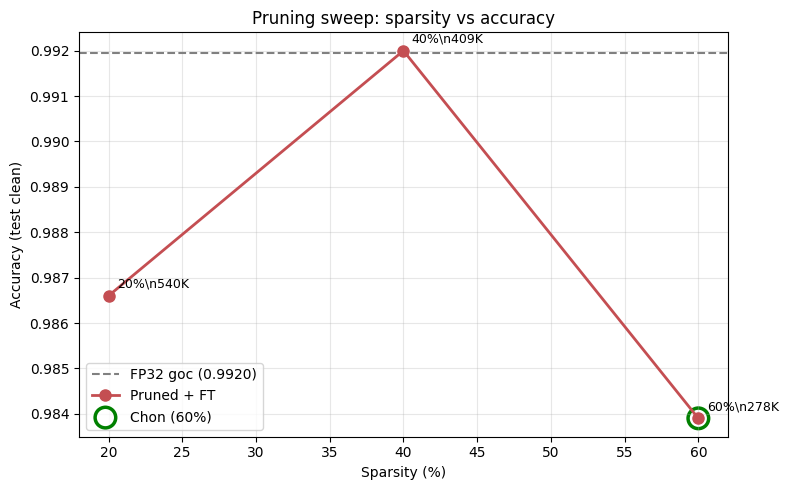

In [19]:
# ===== Duong cong sparsity - accuracy =====
fig, ax = plt.subplots(figsize=(8, 5))
ax.axhline(fp32_acc, ls='--', c='gray', label=f'FP32 goc ({fp32_acc:.4f})')
ax.plot(sweep_df['sparsity_%'], sweep_df['accuracy'], 'o-', c='#C44E52', lw=2, ms=8, label='Pruned + FT')
for _, r in sweep_df.iterrows():
    ax.annotate(f"{int(r['amount']*100)}%\\n{int(r['nonzero_params']/1000)}K", (r['sparsity_%'], r['accuracy']),
                textcoords='offset points', xytext=(6, 6), fontsize=9)
_p = sweep_df[sweep_df['amount'] == PRUNE_PICK].iloc[0]
ax.scatter([_p['sparsity_%']], [_p['accuracy']], s=220, facecolors='none',
           edgecolors='green', lw=2.5, label=f'Chon ({int(PRUNE_PICK*100)}%)')
ax.set_xlabel('Sparsity (%)'); ax.set_ylabel('Accuracy (test clean)')
ax.set_title('Pruning sweep: sparsity vs accuracy'); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.savefig('c14_prune_curve.png', dpi=300, bbox_inches='tight'); plt.show()

In [20]:
# ===== 2/3 — Dynamic PTQ (INT8): luong tu cac lop Linear (chay tren CPU) =====
int8_fp = torch.ao.quantization.quantize_dynamic(
    copy.deepcopy(model_s2).cpu().eval(), {nn.Linear}, dtype=torch.qint8)
int8_pr = torch.ao.quantization.quantize_dynamic(
    copy.deepcopy(pruned).cpu().eval(),   {nn.Linear}, dtype=torch.qint8)
print('INT8 dynamic xong (Linear -> qint8). Conv2d cua MobileNetV2 giu FP32.')

INT8 dynamic xong (Linear -> qint8). Conv2d cua MobileNetV2 giu FP32.


In [21]:
# ===== 3/3 — FP16 (model.half(), chay tren GPU) =====
if gpu is not None:
    fp16 = copy.deepcopy(model_s2).half().to(gpu).eval()
    print('FP16 xong (toan model half-precision).')
else:
    fp16 = None
    print('[!] Khong co GPU -> bo qua FP16.')

FP16 xong (toan model half-precision).


[FP32 (de xuat)    ] total=  671,173 | nonzero=  671,173 |  2.838 MB | sparsity  0.0% | acc 0.9920 | f1 0.9922 | cpu 18.53 ms | gpu 4.89 ms
[Pruned 60% + FT   ] total=  671,173 | nonzero=  278,763 |  2.838 MB | sparsity 60.0% | acc 0.9839 | f1 0.9841 | cpu 18.71 ms | gpu 5.7 ms
[INT8 dynamic      ] total=        - | nonzero=        - |  2.494 MB | sparsity  0.0% | acc 0.9920 | f1 0.9922 | cpu 20.98 ms | gpu None ms
[Pruned + INT8     ] total=        - | nonzero=        - |  2.494 MB | sparsity 59.5% | acc 0.9839 | f1 0.9841 | cpu 21.3 ms | gpu None ms
[FP16              ] total=  671,173 | nonzero=  671,172 |  1.462 MB | sparsity  0.0% | acc 0.9920 | f1 0.9922 | cpu None ms | gpu 5.92 ms

        variant  total_params  nonzero_params  size_MB  sparsity_%  accuracy  f1_macro  lat_cpu_ms  lat_gpu_ms
 FP32 (de xuat)      671173.0        671173.0    2.838         0.0    0.9920    0.9922       18.53        4.89
Pruned 60% + FT      671173.0        278763.0    2.838        60.0    0.9839    

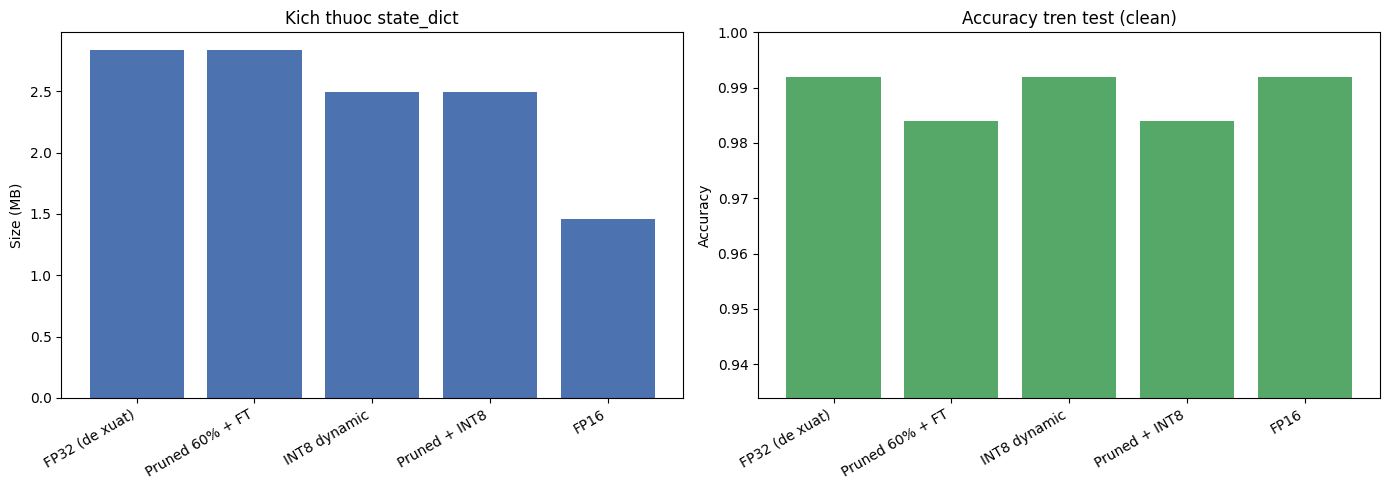

In [22]:
# ===== Cham diem tat ca bien the + bang tong hop =====
compress_rows = []
add_row('FP32 (de xuat)',                       copy.deepcopy(model_s2), base_dev, torch.float32, lat_cpu=True,  lat_gpu_dtype=torch.float32)
add_row(f'Pruned {int(PRUNE_PICK*100)}% + FT',  pruned,                  base_dev, torch.float32, lat_cpu=True,  lat_gpu_dtype=torch.float32)
add_row('INT8 dynamic',                         int8_fp,                 cpu,      torch.float32, lat_cpu=True)
add_row('Pruned + INT8',                        int8_pr,                 cpu,      torch.float32, lat_cpu=True)
if fp16 is not None:
    add_row('FP16',                             fp16,                    gpu,      torch.float16, lat_gpu_dtype=torch.float16)

comp_df = pd.DataFrame(compress_rows)
print('\n' + comp_df.to_string(index=False))
comp_df.to_csv('c14_compression_summary.csv', index=False)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].bar(comp_df['variant'], comp_df['size_MB'], color='#4C72B0')
ax[0].set_ylabel('Size (MB)'); ax[0].set_title('Kich thuoc state_dict'); ax[0].tick_params(axis='x', rotation=30)
ax[1].bar(comp_df['variant'], comp_df['accuracy'], color='#55A868')
ax[1].set_ylabel('Accuracy'); ax[1].set_title('Accuracy tren test (clean)')
ax[1].set_ylim(max(0, comp_df['accuracy'].min() - 0.05), 1.0); ax[1].tick_params(axis='x', rotation=30)
for a in ax:
    for lb in a.get_xticklabels(): lb.set_ha('right')
plt.tight_layout(); plt.savefig('c14_compression_summary.png', dpi=300, bbox_inches='tight'); plt.show()